In [475]:
import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt

In [476]:
vermelho = [43, 53, 194]#2#5
amarelo = [46, 224, 213]#32#66
verde = [115, 174, 3]##160
azul = [210, 179, 82]#96#193

vermelhoo = cv.cvtColor((np.uint8([[vermelho]])), cv.COLOR_BGR2HSV)
amareloo = cv.cvtColor((np.uint8([[amarelo]])), cv.COLOR_BGR2HSV)
verdee = cv.cvtColor((np.uint8([[verde]])), cv.COLOR_BGR2HSV)
azull = cv.cvtColor((np.uint8([[azul]])), cv.COLOR_BGR2HSV)

# print ('vermelho: ' + str(vermelhoo))
# print ('amarelo: ' + str(amareloo))
# print ('verde: ' + str(verdee))
# print ('azul: ' + str((azull)))


vm = vermelhoo[0][0][0]
am = amareloo[0][0][0]
vd = verdee[0][0][0]
az = azull[0][0][0]

print(vm, am, vd, az)

def choosecolor (valorhsv):
    #sobre 2 menos 1
    
    h = int(valorhsv[0])

    dist = [0,0,0,0]

    # print("aaaa")
    # print('this is our h: ' + str(h))

    dist[0] = np.uint8(abs(int(h) - int(vm)))
    dist[1] = np.uint8(abs(int(h) - int(am)))
    dist[2] = np.uint8(abs(int(h) - int(am)))
    dist[3] = np.uint8(abs(int(h) - int(vd)))

    # print("bbbb")

    a = min(dist)
    # print(dist)

    # print(dist)

    # print("current color (" + str(valorhsv[0]) + ", " + str(valorhsv[1]) + ", " + str(valorhsv[2]) + ") is closer to the color of index " + str(dist.index(a)) + " (" + str(a) + " units away)")

    return dist.index(a)






def getcolor (img, c1):

    # for c in circulos[0, :]:

    c = (int(c1[0]),int(c1[1]),int(c1[2]))

    r = int(c[2])
    hues = [0,0,0,0]
    # print(img.shape)

    for i in range(-1*r, r):
        for j in range(-1*r, r):
            if (c[0] + i < 0 or c[0] + i >= img.shape[1] or c[1] + j < 0 or c[1] + j >= img.shape[0]):
                continue
            dist = np.sqrt((i)**2 + (j)**2)
            # print("cheguei aqui 3 e a dist eh igual a " + str(dist))
            if int(dist) <= r and int(dist) >= r*2/3 : # ta dentro da area

                # print('estou no pixel ('+ str(c[1]+j) +', ' + str(c[0]+i) + ')')
                # hues[choosecolor(img[c[0] + i][c[1] + j])]+=1
                # print('cor: ' + str(img[c[1] + j][c[0] + i]))
                a = np.uint8([[img[c[1] + j][c[0] + i]]])
                a = cv.cvtColor(a, cv.COLOR_BGR2HSV)
                # print(a)
                # img[c[1] + j][c[0] + i] = [0, 0, 0]
                if (a[0][0][1] > 15): # se eh suficientemente longe do gray
                #     # print(img[c[0] + i][c[1] + j])
                #     # print(c[0] + i)
                #     # print(c[1] + j)
                    hues[choosecolor(a[0][0])]+=1
                # print()
    # print(hues)
    # print(hues)
                    
    return hues.index(max(hues))

                


    # for i in circulos[0, :]:
    # cv.circle(imgfinal, (i[0], i[1]), i[2], (0, 255, 0), 1)

    # cv.circle(imgfinal, (i[0], i[1]), int(np.around(2*i[2]/3)), (0, 255, 0), 1)

    # cv.circle(imgfinal, (i[0],i[1]), 2, (0, 0, 255), 3)

2 32 80 97


168 166 165
10 5 168


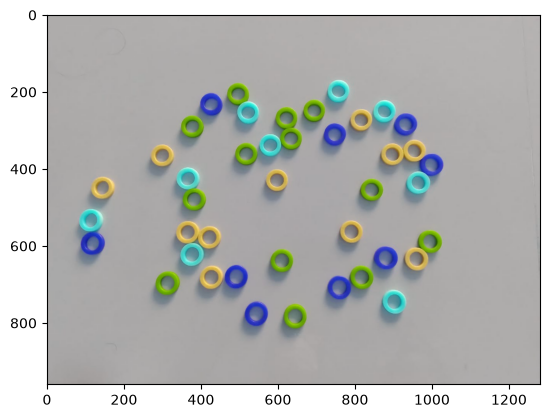

In [477]:
filepath = "../img/1.jpg"
img = cv.imread(filepath)
print(img[815][449][0], img[815][449][1], img[815][449][2])
# img = cv.cvtColor(img, cv.COLOR_BGR2RGB)
# print(img[815][449][0], img[815][449][1], img[815][449][2])
imghsv = cv.cvtColor(img, cv.COLOR_RGB2HSV)
print(imghsv[815][449][0], imghsv[815][449][1], imghsv[815][449][2])
# hue vai nos ajudar mais do que rgb!
imgray = cv.cvtColor(img, cv.COLOR_RGB2GRAY)
plt.imshow(img)
imgray = cv.GaussianBlur(imgray, (7, 7), 1.5)

In [478]:

teste = np.zeros((300,512,3), np.uint8)
teste[:] = [114, 7, 171]#[102, 133, 34]#[161,74,52]
teste = cv.cvtColor(teste, cv.COLOR_BGR2RGB)
cor = [114, 7, 171]#[110, 5, 168]#[102, 133, 34]
corr = np.uint8([[cor]])
corr = cv.cvtColor(corr, cv.COLOR_BGR2HSV)
print(corr[0][0][0], corr[0][0][1], corr[0][0][2])
# cv.imshow('', teste)
# cv.waitKey(0)
# cv.destroyAllWindows()

160 245 171


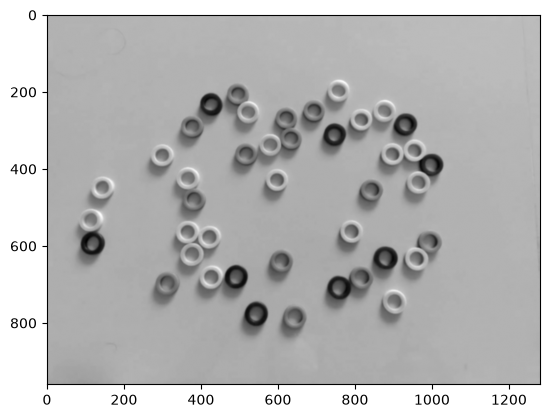

In [479]:
plt.imshow(imgray, cmap='gray')

In [480]:
circulos = cv.HoughCircles(imgray, cv.HOUGH_GRADIENT, 1, 20, param1=50, param2=30, minRadius=10, maxRadius=40)
circulosinternos = cv.HoughCircles(imgray, cv.HOUGH_GRADIENT,20, 20, param1=50, param2=50, minRadius=15, maxRadius=25)


In [481]:
circulos = np.uint16(np.around(circulos))
print(circulos.shape)
# circulosinternos = np.uint16(np.around(circulosinternos))
# print(circulosinternos.shape)

imgfinal = img

# imgfinalinternos = img.copy()

cores = [0,0,0,0]

contador = 0

for i in circulos[0, :]:
    contador+=1
    a = getcolor(imgfinal, i)
    cor = (0,0,0)
    s = "a cor selecionada foi: "
    match a:
        case 0:
            cor = (54, 54, 255)
            cores[0]+=1
        case 1:
            cor = (50, 255, 255)
            cores[1]+=1
            # print(s + "amarelo")
        case 2:
            cor = (81, 255, 54)
            cores[2]+=1
            # print(s + "verde")
        case 3:
            cor = (255, 108, 54)
            cores[3]+=1
            # print(s + "azul")
        
    cv.circle(imgfinal, (i[0], i[1]), i[2], cor, 1)

    cv.circle(imgfinal, (i[0], i[1]), int(np.around(2*i[2]/3)), cor, 1)

    cv.circle(imgfinal, (i[0],i[1]), 2, cor, 3)

    # if (contador >= 9):
    #     break
    # break;
    
    

# for i in circulosinternos[0, :]:
#     cv.circle(imgfinalinternos, (i[0], i[1]), i[2], (0, 255, 0), 1)

#     cv.circle(imgfinalinternos, (i[0],i[1]), 2, (0, 0, 255), 3)
print(cores)

(1, 42, 3)
[9, 9, 0, 24]


to do: DEBUGAR OS VERDES!!!!!! lowkey eh porque eh um tom de verde proximo demais do azul ai dificulta um pouco

In [482]:
# print(circulos)

In [483]:
# print(circulosinternos)

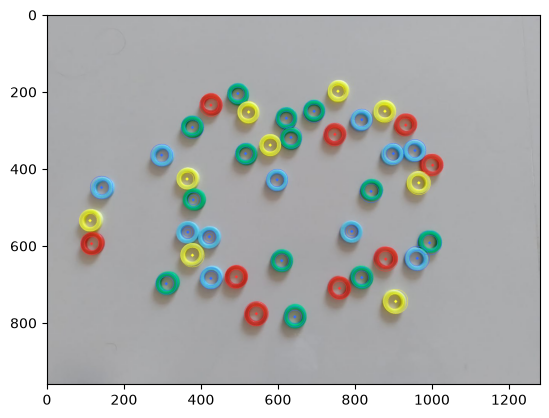

In [484]:
# imgfinal = cv.cvtColor(imgfinal, cv.COLOR_HSV2RGB)
imgfinal = cv.cvtColor(imgfinal, cv.COLOR_BGR2RGB)
plt.imshow(imgfinal)

In [485]:
# plt.imshow(imgfinalinternos)
print(imghsv[0][0])

[ 10   4 174]


ok entao temos os centros, os raios possivelmente errados e a imagem em hsv

no entanto! temos que a proporcao entre o raio interno e externo eh constante

posso pegar a moda de todos os pixels? vai ser O(t*40^2)